In [1]:
!pip install -q datasets insightface opencv-python pandas matplotlib

In [2]:
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

C:\Users\akars\Capstone\test\YOLO11\myvenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import os
path="Capstone/AI_Intruder_Capstone/datasets/widerface/data"
for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}  {file}")

In [4]:
import os

for root, dirs, files in os.walk(path):
    print(root)
    for f in files[:10]:
        print("   ", f)

In [6]:
from pathlib import Path

dataset_dir = Path(r"Datasets\widerface\data")

image_paths = list(
    dataset_dir.glob("WIDER_val/**/*.jpg")
)

print("Number of validation images:", len(image_paths))
print("First 5 images:")

for path in image_paths[:5]:
    print(path)

Number of validation images: 3226
First 5 images:
Datasets\widerface\data\WIDER_val\images\0--Parade\0_Parade_marchingband_1_1004.jpg
Datasets\widerface\data\WIDER_val\images\0--Parade\0_Parade_marchingband_1_104.jpg
Datasets\widerface\data\WIDER_val\images\0--Parade\0_Parade_marchingband_1_1045.jpg
Datasets\widerface\data\WIDER_val\images\0--Parade\0_Parade_marchingband_1_139.jpg
Datasets\widerface\data\WIDER_val\images\0--Parade\0_Parade_marchingband_1_147.jpg


In [7]:
from PIL import Image

image = Image.open(image_paths[0])

print("Image size:", image.size)

image.show()

Image size: (1024, 768)


In [8]:
from datasets import Dataset

wider = Dataset.from_dict({
    "image": [str(path) for path in image_paths]
})

print(wider)

Dataset({
    features: ['image'],
    num_rows: 3226
})


In [9]:
print(wider[0])

{'image': 'Datasets\\widerface\\data\\WIDER_val\\images\\0--Parade\\0_Parade_marchingband_1_1004.jpg'}


In [10]:
from PIL import Image

image = Image.open(wider[0]["image"])
image.show()

In [11]:

print(wider)

Dataset({
    features: ['image'],
    num_rows: 3226
})


In [12]:
print(wider.features)

{'image': Value('string')}


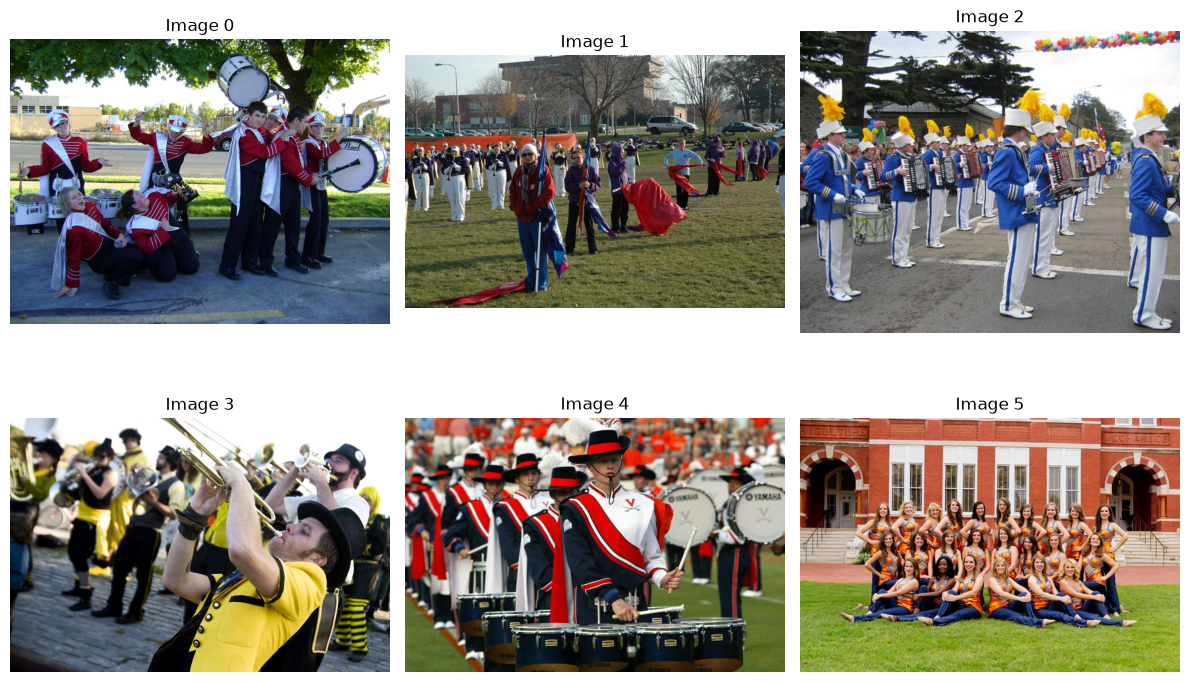

In [13]:
from PIL import Image
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i in range(6):
    sample = wider[i]

    image = Image.open(sample["image"])

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Image {i}")

plt.tight_layout()
plt.show()

In [14]:
sample = wider[0]

for key, value in sample.items():

    print("\n", key)

    if hasattr(value, "shape"):
        print("Shape:", value.shape)

    else:
        print(type(value))


 image
<class 'str'>


In [15]:
from insightface.app import FaceAnalysis

face_app = FaceAnalysis(
    name="buffalo_s",
    providers=["CPUExecutionProvider"]
)

face_app.prepare(ctx_id=-1)

download_path: C:\Users\akars/.insightface\models\buffalo_s


100%|██████████| 124617/124617 [02:19<00:00, 895.60KB/s] 


In [18]:
# sample = wider[0]

# image = np.array(sample["image"])

# faces = face_app.get(image)

# print("Faces detected:", len(faces))

In [17]:
sample = wider[0]

print(type(sample["image"]))
print(sample["image"])

<class 'str'>
Datasets\widerface\data\WIDER_val\images\0--Parade\0_Parade_marchingband_1_1004.jpg


In [19]:
from PIL import Image
import numpy as np

sample = wider[0]

image = np.array(Image.open(sample["image"]).convert("RGB"))

print(type(image))
print(image.shape)

faces = face_app.get(image)

print("Faces detected:", len(faces))

<class 'numpy.ndarray'>
(768, 1024, 3)


C:\Users\akars\Capstone\test\YOLO11\myvenv\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


Faces detected: 5


In [20]:
from PIL import Image
import numpy as np
import cv2

sample = wider[0]

# Load local image
image = np.array(
    Image.open(sample["image"]).convert("RGB")
)

# RGB -> BGR for InsightFace
image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)

print("Image shape:", image.shape)

# Face detection
faces = face_app.get(image)

print("Faces detected:", len(faces))

for face in faces:
    print("Bounding box:", face.bbox)
    print("Detection score:", face.det_score)

Image shape: (768, 1024, 3)
Faces detected: 5
Bounding box: [647.6405  190.99681 688.16895 237.88066]
Detection score: 0.8610471
Bounding box: [811.3064  224.35086 844.52673 263.4903 ]
Detection score: 0.7873931
Bounding box: [157.99535 407.11694 202.32333 459.11554]
Detection score: 0.7353948
Bounding box: [772.781   206.84612 806.24774 252.6064 ]
Detection score: 0.669369
Bounding box: [120.33885 219.13191 157.05661 258.9424 ]
Detection score: 0.6214532


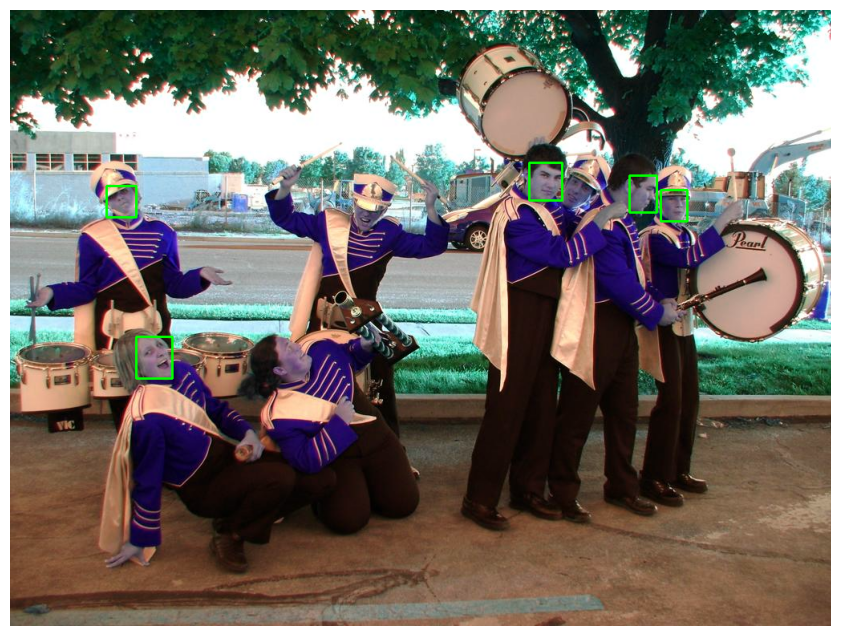

In [25]:
import cv2
image_display = image.copy()

for face in faces:

    bbox = face.bbox.astype(int)

    x1, y1, x2, y2 = bbox

    cv2.rectangle(
        image_display,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(12, 8))

plt.imshow(image_display)
plt.axis("off")
plt.show()